In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df= pd.read_csv('/content/customer_churn_nlp.csv')
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]}coloumns\n")
print(" First 5 customer profiles:")
df.head()
df.shape

Dataset Shape: 500 rows, 7coloumns

 First 5 customer profiles:


(500, 7)

Text(0.5, 1.0, 'Churn Rate Breakdown')

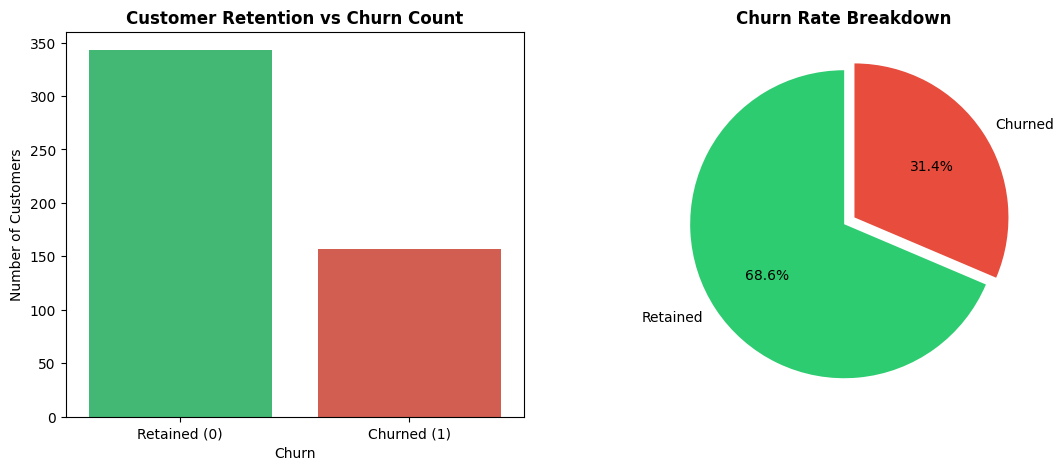

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.countplot(data=df, x='Churn', palette=['#2ecc71', '#e74c3c'], ax=axes[0])
axes[0].set_title('Customer Retention vs Churn Count', fontsize=12, fontweight='bold')
axes[0].set_xticklabels(['Retained (0)', 'Churned (1)'])
axes[0].set_ylabel('Number of Customers')
churn_counts = df['Churn'].value_counts()
axes[1].pie(churn_counts, labels=['Retained', 'Churned'], autopct='%1.1f%%',
            colors=['#2ecc71', '#e74c3c'], startangle=90, explode=(0, 0.08))
axes[1].set_title('Churn Rate Breakdown', fontsize=12, fontweight='bold')

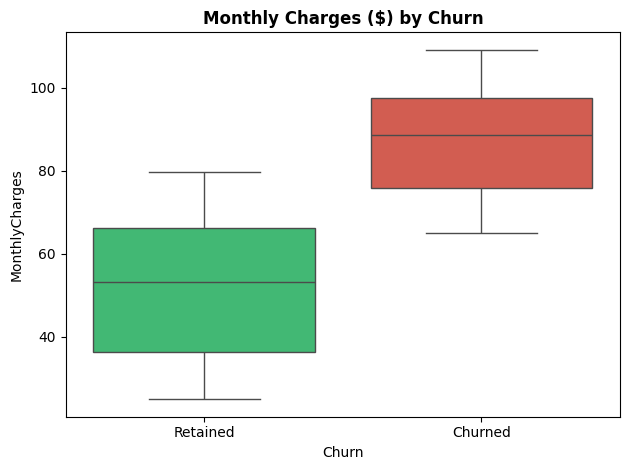

In [ ]:
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', palette=['#2ecc71', '#e74c3c'])

plt.title('Monthly Charges ($) by Churn', fontweight='bold')

plt.xticks([0,1], ['Retained', 'Churned'])

plt.tight_layout()

plt.show()

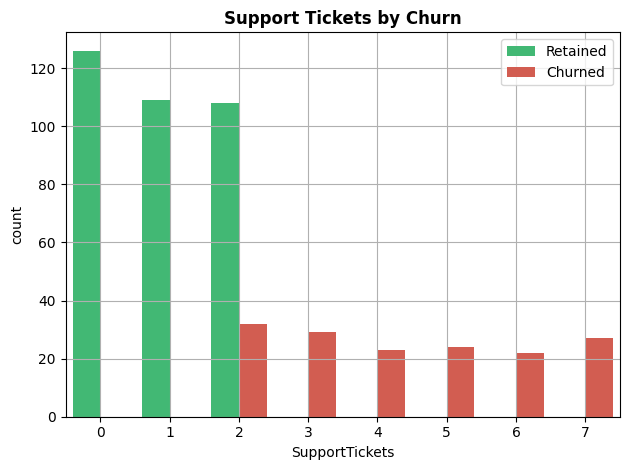

In [ ]:
sns.countplot(data=df, x='SupportTickets', hue='Churn', palette=['#2ecc71', '#e74c3c']) # Added a second color and closed the palette list
plt.title('Support Tickets by Churn', fontweight='bold')
plt.legend(['Retained', 'Churned'])
plt.tight_layout()
plt.grid()
plt.show()

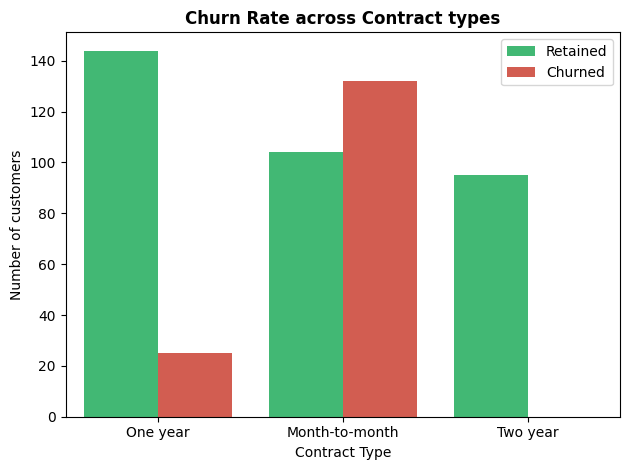

In [ ]:
sns.countplot(data=df, x='Contract', hue='Churn', palette=['#2ecc71', '#e74c3c'])
plt.title('Churn Rate across Contract types', fontweight='bold')
plt.xlabel('Contract Type')
plt.ylabel('Number of customers')
plt.legend(['Retained', 'Churned'])
plt.tight_layout()
plt.show()

In [ ]:
print("---Siraaaa🔥 Feedback from Retained Customers---")
for text in df[df['Churn'] == 0]['CustomerFeedback'][:3]:
    print(text)
print("\n---Gandye🤮 Feedback from Churned Customers---")
for text in df[df['Churn']==1]['CustomerFeedback'].head(3):
  print(f"[Churned]: {text}")

---Siraaaa🔥 Feedback from Retained Customers---
Customer support was very helpful and polite.
Smooth connection and fair monthly prices.
Excellent coverage and fast streaming experience.

---Gandye🤮 Feedback from Churned Customers---
[Churned]: Bad experience, moving to another provider soon.
[Churned]: Cancel my subscription, worst customer care ever.
[Churned]: Monthly charges are way too expensive for bad service.


In [ ]:
df_contract_encoded = pd.get_dummies(df[['Contract']], drop_first=True, dtype=int)
tfidf_vectorizer = TfidfVectorizer(max_features=15, stop_words='english', ngram_range=(1, 2))
text_features = tfidf_vectorizer.fit_transform(df['CustomerFeedback']).toarray()
text_feature_names = [f"text_{word}" for word in tfidf_vectorizer.get_feature_names_out()]
df_text_encoded = pd.DataFrame(text_features, columns=text_feature_names)
print(df_text_encoded)
df_numeric = df[['Tenure', 'MonthlyCharges', 'SupportTickets']]
x= pd.concat([df_numeric, df_contract_encoded, df_text_encoded], axis=1)
y= df['Churn']
print(f"Combined Features Matrix X shape: {x.shape[0]}, samples, {x.shape[1]} features")
print("\nFeatures Column List:")
print(list(x.columns))

     text_care  text_connection  text_customer  text_customer care  \
0          0.0         0.000000            1.0                 0.0   
1          0.0         0.710409            0.0                 0.0   
2          0.0         0.000000            0.0                 0.0   
3          0.0         0.000000            0.0                 0.0   
4          0.0         0.000000            0.0                 0.0   
..         ...              ...            ...                 ...   
495        0.0         0.000000            0.0                 0.0   
496        0.0         0.000000            0.0                 0.0   
497        0.0         0.000000            0.0                 0.0   
498        0.0         1.000000            0.0                 0.0   
499        0.0         0.000000            0.0                 0.0   

     text_excellent  text_excellent coverage  text_experience  text_fast  \
0          0.000000                 0.000000         0.000000   0.000000   
1      

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    x,y, test_size=0.20, random_state=42, stratify=y
)
print(f"Training set size: {x_train.shape[0]} samples")
print(f"Testing set size : {x_test.shape[0]} samples\n")
model_lr = LogisticRegression(max_iter=1000, random_state=42)
model_lr.fit(x_train, y_train)
y_pred_lr = model_lr.predict(x_test)
acc_lr = accuracy_score(y_test, y_pred_lr)

Training set size: 400 samples
Testing set size : 100 samples



In [ ]:
model_rf = RandomForestClassifier(n_estimators=100, random_state=42)
model_rf.fit(x_train, y_train)
y_pred_rf = model_rf.predict(x_test)
acc_rf = accuracy_score(y_test, y_pred_rf)
print(f"Logistic Regression Accuracy: {acc_lr*100:.2f}%")
print(f"Random Forest Accuracy: {acc_rf*100:.2f}%")

Logistic Regression Accuracy: 100.00%
Random Forest Accuracy: 100.00%


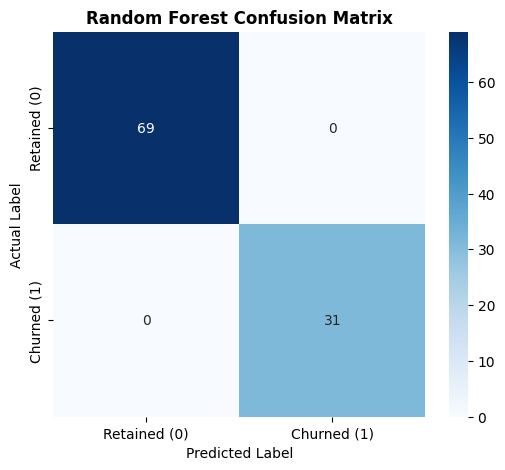

--- Detailed Classification Report (Random Forest) ---
              precision    recall  f1-score   support

Retained (0)       1.00      1.00      1.00        69
 Churned (1)       1.00      1.00      1.00        31

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100



In [ ]:
# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Retained (0)', 'Churned (1)'],
            yticklabels=['Retained (0)', 'Churned (1)'])
plt.title('Random Forest Confusion Matrix', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

# Classification Report
print("--- Detailed Classification Report (Random Forest) ---")
print(classification_report(y_test, y_pred_rf, target_names=['Retained (0)', 'Churned (1)']))

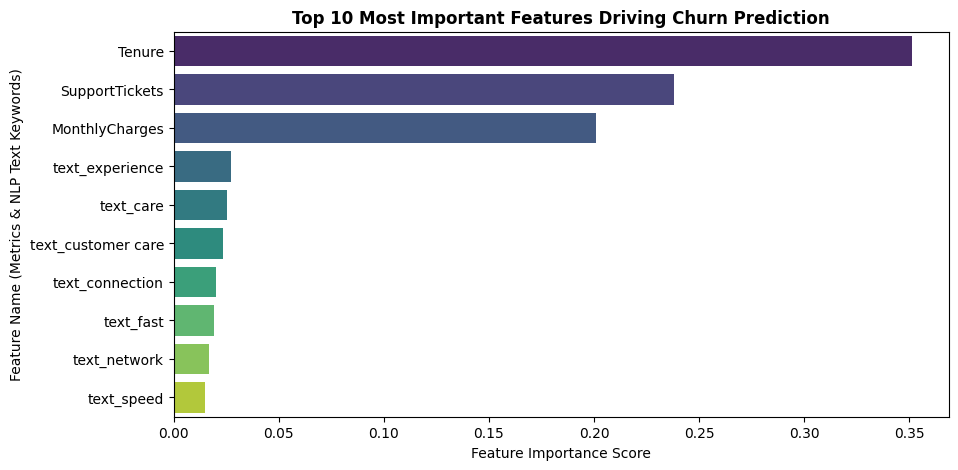

In [ ]:
# Feature Importance Analysis (Which usage metrics & text keywords matter most?)
feature_importances = pd.Series(model_rf.feature_importances_, index=x.columns)
top_features = feature_importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_features.values, y=top_features.index, palette='viridis')
plt.title('Top 10 Most Important Features Driving Churn Prediction', fontsize=12, fontweight='bold')
plt.xlabel('Feature Importance Score')
plt.ylabel('Feature Name (Metrics & NLP Text Keywords)')
plt.show()

In [ ]:
def predict_customer_churn(tenure, monthly_charges, support_tickets, contract_type, feedback_text):
    # 1. Create base numerical dictionary
    input_dict = {
        'Tenure': [tenure],
        'MonthlyCharges': [monthly_charges],
        'SupportTickets': [support_tickets],
        'Contract_One year': [1 if contract_type == 'One year' else 0],
        'Contract_Two year': [1 if contract_type == 'Two year' else 0]
    }

    # 2. Transform text using fitted TF-IDF Vectorizer
    text_vectorized = tfidf_vectorizer.transform([feedback_text]).toarray()
    for i, col_name in enumerate(text_feature_names):
        input_dict[col_name] = [text_vectorized[0][i]]

    # 3. Create single row DataFrame matching training features
    df_input = pd.DataFrame(input_dict)[x.columns]

    # 4. Predict Churn Probability using Random Forest Model
    churn_prob = model_rf.predict_proba(df_input)[0][1]
    is_churn = churn_prob >= 0.5

    print("=" * 60)
    print("         CUSTOMER CHURN RISK ASSESSMENT REPORT          ")
    print("=" * 60)
    print(f" Customer Input Profile:")
    print(f"   • Tenure           : {tenure} months")
    print(f"   • Monthly Bill     : ${monthly_charges:.2f}")
    print(f"   • Support Tickets  : {support_tickets}")
    print(f"   • Contract Type    : {contract_type}")
    print(f'   • Feedback Review  : {feedback_text}')
    print("-" * 60)
    print(f' CHURN PROBABILITY: {churn_prob*100:.1f}%')
    if is_churn:
        print(" RISK STATUS  : HIGH RISK OF CHURN (DABGER)")
        print(" suggested action : trigger rentention offer!")
        print("                                 ->offer 15%discount on 1 year contract.")
        print("                                 ->Schedule priority customer support callback.")
    else :
        print("RISK STATUS   :RETAINED (LOW RISK)")
        print("suggested action : no intervention needed. send thank you offer.")
    print("="*60)

In [ ]:
predict_customer_churn(
    tenure=2,
    monthly_charges=95.50,
    support_tickets=5,
    contract_type='Month-to-month',
    feedback_text="Terrible internet speed, disconnects constantly! Overpriced charges."
)

print("\n")

# --- Test Case 2: Low Risk Customer (Long tenure, reasonable charges, good feedback) ---
predict_customer_churn(
    tenure=36,
    monthly_charges=45.00,
    support_tickets=0,
    contract_type='Two year',
    feedback_text="Love the service, smooth connection and very helpful customer care !"
)

         CUSTOMER CHURN RISK ASSESSMENT REPORT          
 Customer Input Profile:
   • Tenure           : 2 months
   • Monthly Bill     : $95.50
   • Support Tickets  : 5
   • Contract Type    : Month-to-month
   • Feedback Review  : Terrible internet speed, disconnects constantly! Overpriced charges.
------------------------------------------------------------
 CHURN PROBABILITY: 100.0%
 RISK STATUS  : HIGH RISK OF CHURN (DABGER)
 suggested action : trigger rentention offer!
                                 ->offer 15%discount on 1 year contract.
                                 ->Schedule priority customer support callback.


         CUSTOMER CHURN RISK ASSESSMENT REPORT          
 Customer Input Profile:
   • Tenure           : 36 months
   • Monthly Bill     : $45.00
   • Support Tickets  : 0
   • Contract Type    : Two year
   • Feedback Review  : Love the service, smooth connection and very helpful customer care !
------------------------------------------------------------
 CH